# Feature selection algorithms comparison
Comparing different supervised feature selection methods for classification problems, using conventional flat features.

In [41]:
import pandas as pd
statdata = pd.read_csv('./data/statdata.csv')
statdata

,cpu_time,feature_rank,ranking_method,replica_no,name,description,recall,precision,fpr,f1,auc
0,3.855204,4.0,RFE w/XGBoost,1,Continuous Features,"Continuous Features [p=20,n=1600,p_=2,h=0.4,ed...",1.0,0.333333,0.222222,0.500000,0.888889
1,3.855204,11.0,RFE w/XGBoost,1,Continuous Features,"Continuous Features [p=20,n=1600,p_=2,h=0.4,ed...",1.0,0.100000,1.000000,0.181818,0.500000
2,3.855204,5.0,RFE w/XGBoost,1,Continuous Features,"Continuous Features [p=20,n=1600,p_=2,h=0.4,ed...",1.0,0.250000,0.333333,0.400000,0.833333
3,3.855204,3.0,RFE w/XGBoost,1,Continuous Features,"Continuous Features [p=20,n=1600,p_=2,h=0.4,ed...",1.0,0.500000,0.111111,0.666667,0.944444
4,3.855204,11.0,RFE w/XGBoost,1,Continuous Features,"Continuous Features [p=20,n=1600,p_=2,h=0.4,ed...",1.0,0.100000,1.000000,0.181818,0.500000
...,...,...,...,...,...,...,...,...,...,...,...
750978,24.113497,2.0,MultiSURF,24,2 Additive Main Effects,"2 Additive Main Effects [p=20,n=1600,p_=2,h=0....",1.0,1.000000,0.000000,1.000000,1.000000
750979,24.113497,1.0,MultiSURF,24,2 Additive Main Effects,"2 Additive Main Effects [p=20,n=1600,p_=2,h=0....",0.5,1.000000,0.000000,0.666667,0.750000
750980,24.860639,1.0,FeatBoost,24,2 Additive Main Effects,"2 Additive Main Effects [p=20,n=1600,p_=2,h=0....",0.0,0.000000,0.050000,NaN,0.475000
750981,24.860639,2.0,FeatBoost,24,2 Additive Main Effects,"2 Additive Main Effects [p=20,n=1600,p_=2,h=0....",0.5,0.500000,0.052632,0.500000,0.723684


In [45]:
print(statdata.shape)
# subset = statdata.copy()
subset = statdata[statdata['name'] != 'Missing Values']
subset = subset[subset['name'] != 'Continuous Endpoints (Threshold)']
subset = subset[subset['name'] != 'Continuous Endpoints (GAMETES)']
subset = subset[subset['ranking_method'] != 'Stability Selection']
# subset = subset[subset['description'].str.contains('h=1')]
print(subset.shape)

(750983, 11)
(745593, 11)


In [46]:
import seaborn as sns
import matplotlib.pyplot as plt

F1 scores

Text(0.5, 1.0, 'f1 scores per unique dataset')

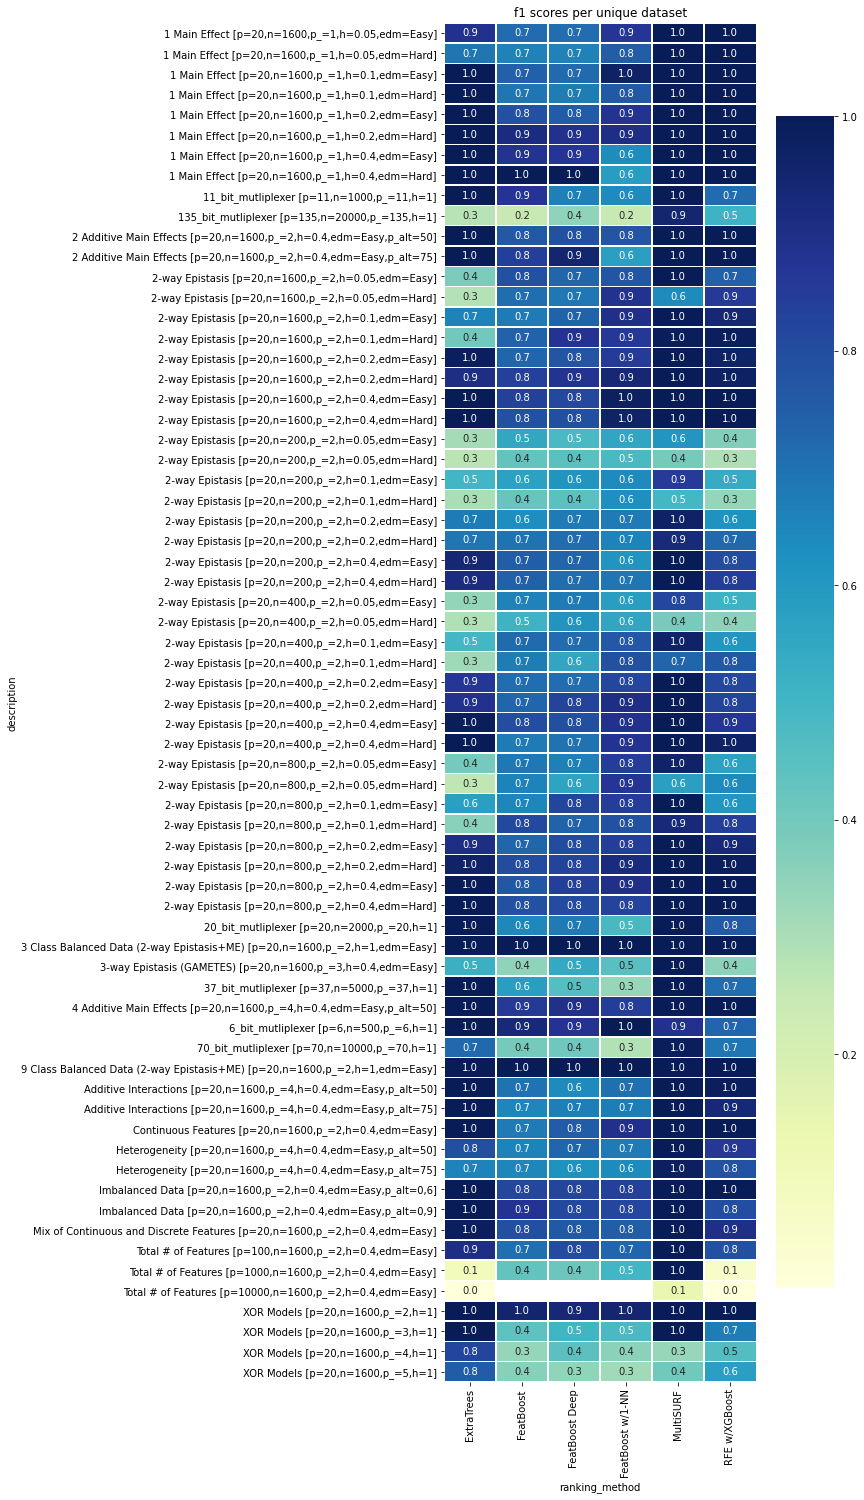

In [100]:
max_f1 = subset.groupby(['description', 'ranking_method', 'replica_no']).agg({'f1': 'max'})
mean_f1 = max_f1.reset_index().groupby(['description', 'ranking_method']).agg({'f1': 'mean'})
maxmean = mean_f1.reset_index()

rectangular = pd.pivot_table(maxmean,\
    values='f1',\
    index=['description'],\
    columns=['ranking_method'])
f, ax = plt.subplots(figsize=(7, 25))
plt.yticks(rotation=0)
plt.xticks(rotation=0)
ax = sns.heatmap(rectangular, annot=True, fmt=".1f", linewidths=.5, cmap="YlGnBu", yticklabels=True, ax=ax)
plt.title('f1 scores per unique dataset')

PR and ROC Curve

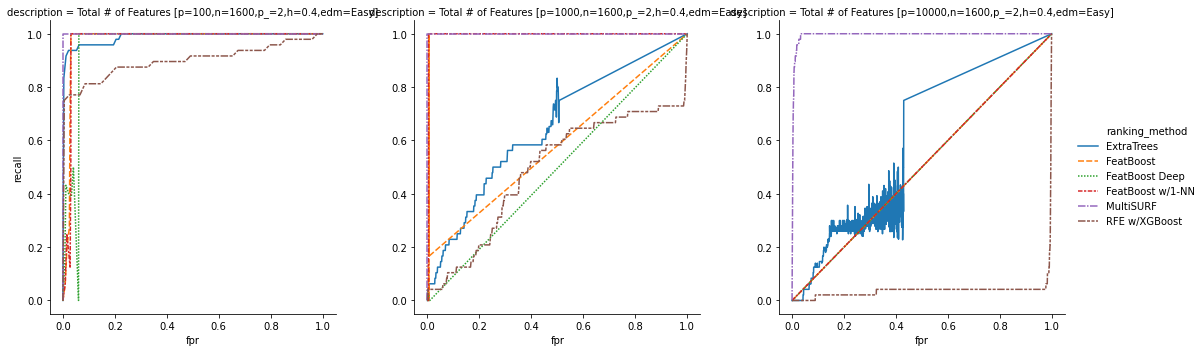

In [81]:
small_subset = subset
small_subset = subset[(subset['name'] == 'Total # of Features')
            #  & (small_subset['description'] == 'Total # of Features [p=10000,n=1600,p_=2,h=0.4,edm=Easy]')
             ]
res = small_subset.groupby(['description', 'ranking_method', 'feature_rank'])\
                  .agg({'recall': 'mean', 'fpr': 'mean'})\
                  .reset_index()

extrarows = []
for key, data in res.groupby(['description', 'ranking_method']):
    descr, rm = key

    dat = pd.DataFrame(data={
        'description': descr,
        'ranking_method': rm,
        'recall': [0, 1],
        'fpr': [0, 1]
    })
    extrarows.append(dat)
res = pd.concat([res, pd.concat(extrarows)])

g = sns.relplot(x='fpr', y='recall', hue='ranking_method', style='ranking_method',
                col='description', kind='line', estimator=None,
                data=res, col_wrap=3, facet_kws={'sharex': False, 'sharey': False})

In [109]:
subset[
            (subset['ranking_method']=='FeatBoost')
            #  (subset['description'] == 'Total # of Features [p=10000,n=1600,p_=2,h=0.4,edm=Easy]') &
              & (subset['description'] == '1 Main Effect [p=20,n=1600,p_=1,h=0.05,edm=Easy]')
            #   & (subset['replica_no']==1)
             ].sort_values('feature_rank').to_csv('e.csv')

Text(0.5, 1.0, 'AUC score per dataset')

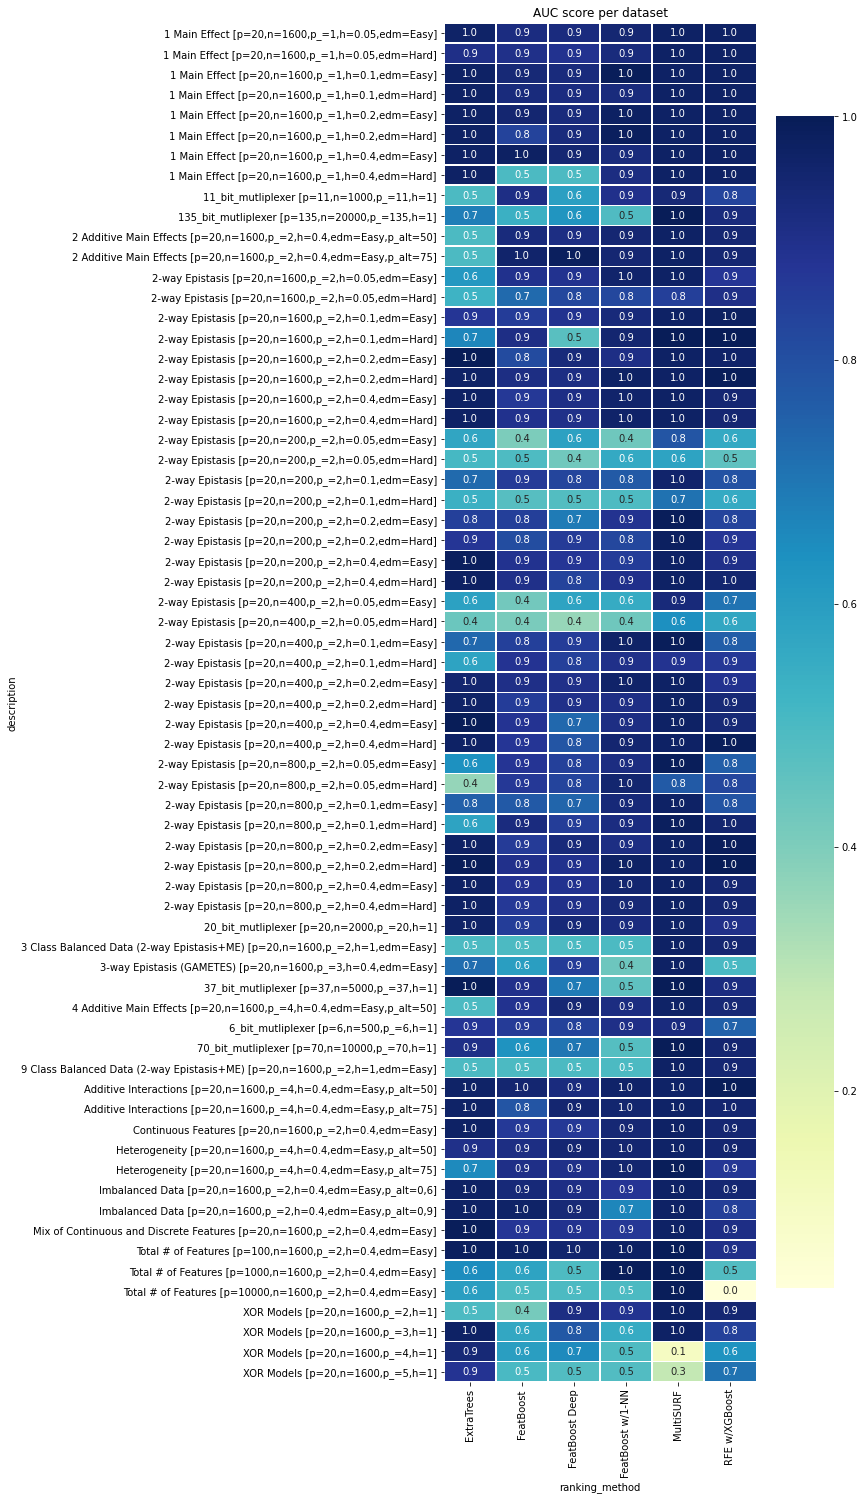

In [117]:
import numpy as np
res2 = subset.groupby(['description', 'ranking_method', 'feature_rank']).agg({'recall': 'mean', 'fpr': 'mean'}).reset_index()

aucs_df = pd.DataFrame()
chunks = []
for key, data in res2.groupby(['description', 'ranking_method']):
    descr, rm = key

    data = data.append(pd.DataFrame(data={ 'fpr': [0, 1], 'recall': [0, 1] }))
    sorted_data = data.sort_values('fpr')

    real_auc = np.trapz(sorted_data.recall.values, sorted_data.fpr.values)
    chunks.append(pd.DataFrame(data={
        'description': descr,
        'ranking_method': rm,
        'auc': [real_auc]
    }))
aucs_df = pd.concat(chunks)
del chunks

rectangular = pd.pivot_table(aucs_df,\
    values='auc',\
    index=['description'],\
    columns=['ranking_method'])
f, ax = plt.subplots(figsize=(7, 25))
plt.yticks(rotation=0)
plt.xticks(rotation=0)
g = sns.heatmap(rectangular,\
    annot=True, fmt=".1f", linewidths=.5, cmap="YlGnBu", yticklabels=True, ax=ax)
plt.title('AUC score per dataset')
    # print('aggregated auc = ', np.mean(data.auc))

In [ ]:
small_subset = subset[subset['description'].str.contains('h=1')]
# small_subset = subset
zero_points = small_subset.copy()
zero_points['roc_fpr'] = 0
zero_points['roc_tpr'] = 0
one_points = small_subset.copy()
one_points['roc_fpr'] = 1
one_points['roc_tpr'] = 1
entire_subset = pd.concat([small_subset, zero_points, one_points])
# pr curve
# g = sns.relplot(x='recall', y='precision', hue='ranking_method', style='ranking_method',
#                 col='description', kind='line', err_style=None,
#                 data=small_subset, col_wrap=3, facet_kws={'sharex': False, 'sharey': False})
# roc curve
g = sns.relplot(x='roc_fpr', y='roc_tpr', hue='ranking_method', style='ranking_method',
                col='description', kind='line',
                data=entire_subset, col_wrap=3, facet_kws={'sharex': False, 'sharey': False})
# g.fig.suptitle('ROC curves (replica aggregation = mean)')
plt.show()

rectangular = pd.pivot_table(entire_subset,\
    values='auc',\
    index=['description'],\
    columns=['ranking_method'])
g = sns.heatmap(rectangular,\
    linewidths=.5, cmap="YlGnBu")
plt.yticks(rotation=0)
plt.xticks(rotation=45)
# plt.gca().xaxis.set_major_formatter(FuncFormatter(lambda x, _: int(x) + 1))
plt.title('AUC scores (replica aggregation = mean)')

1428      20_bit_mutliplexer
1429      20_bit_mutliplexer
1430      20_bit_mutliplexer
1431      20_bit_mutliplexer
1432      20_bit_mutliplexer
                 ...        
162032            XOR Models
162033            XOR Models
162034            XOR Models
162035            XOR Models
162036            XOR Models
Name: name, Length: 25771, dtype: object
[0.         0.05050505 0.06060606 0.1010101  0.11111111 0.12121212
 0.16161616 0.17171717 0.19191919 0.21212121 0.22222222 0.23232323
 0.25252525 0.26262626 0.27272727 0.29292929 0.31313131 0.33333333
 0.37373737 0.38383838 0.43434343 0.49494949 0.56565657 1.        ]
values= [0.09051724137931035, 0.13260423786739578, 0.8966224747474748, 0.19214365881032544, 0.5, 0.8968013468013467, 0.3856195887445888, 0.7297979797979799, 1.0, 0.2515151515151515, 0.5, 0.7405303030303031, 1.0, 0.24949494949494955, 0.4909090909090909, 0.7469696969696971, 1.0, 0.5, 0.9966329966329966, 0.4935064935064935, 0.9927849927849928, 0.98989898989899, 1.0, 1.0]


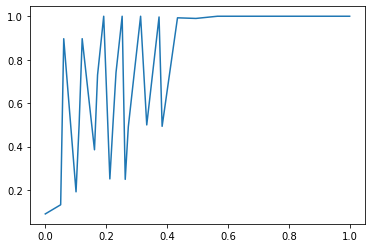

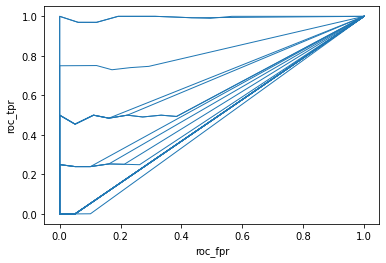

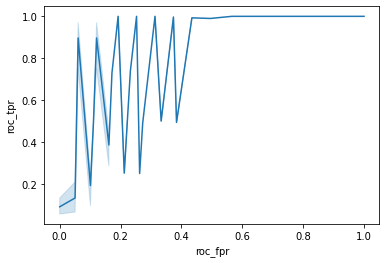

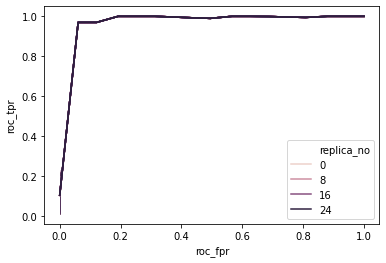

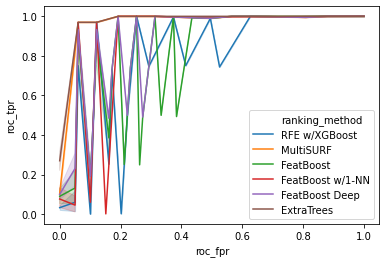

In [73]:
### VAlidating correctness of plot
supersmally = entire_subset[entire_subset['name'] == '20_bit_mutliplexer']
supersmall = supersmally[supersmally['ranking_method'] == 'FeatBoost']
fprs = np.array(supersmall['roc_fpr'])
tprs = np.array(supersmall['roc_tpr'])
import numpy as np
slots = np.unique(fprs)
print(slots)
values = []
for slot in slots:
    idxes = np.where(fprs == slot)[0]
    aggr = np.mean(tprs[idxes])
    values.append(aggr)
print('values=', values)
plt.plot(slots, values)
plt.show()
sns.lineplot(data=supersmall, x='roc_fpr', y='roc_tpr', units='replica_no', estimator=None, lw=1)
plt.show()
sns.lineplot(data=supersmall, x='roc_fpr', y='roc_tpr')
plt.show()
supersmall2 = supersmally[supersmally['ranking_method'] == 'MultiSURF']
sns.lineplot(data=supersmall2, x='roc_fpr', y='roc_tpr', hue='replica_no')
plt.show()
sns.lineplot(data=supersmally, x='roc_fpr', y='roc_tpr', hue='ranking_method')
plt.show()

Text(0.5, 1.0, 'recall per ranking method for all datasets')

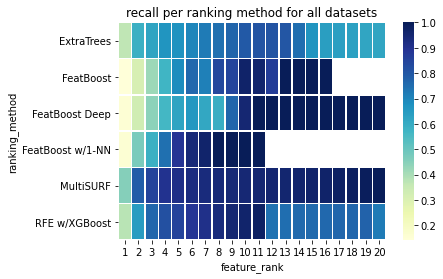

In [7]:
subset2 = subset[subset['feature_rank'] <= 20]

from matplotlib.ticker import FuncFormatter
rectangular = pd.pivot_table(subset2,\
    values='recall',\
    index=['ranking_method'],\
    columns=['feature_rank'])
g = sns.heatmap(rectangular,\
    linewidths=.5, cmap="YlGnBu")
plt.yticks(rotation=0)
plt.xticks(rotation=0)
plt.gca().xaxis.set_major_formatter(FuncFormatter(lambda x, _: int(x) + 1))
plt.title('recall per ranking method for all datasets')

Construct a sensible subset for plotting

In [55]:
# subset = statdata.copy()
# for dataset, data in statdata.groupby('description'):
#     all_replicas = data.groupby('replica_no')
#     if len(all_replicas.count()) != 24: # only 'finished' datasets
#         subset = subset[subset['description'] != dataset]
#     else: # add newline in plot title
#         descr = dataset.replace(' [p=', '\n[p=')
#         descr = descr.replace(',h=', ',\nh=')
#         subset = subset.replace({ 'description': dataset }, descr)
#         # short_descr = '[p=' + dataset.split(' [p=')[1]
#         # entries = subset[subset['description'] == dataset]
#         # subset.loc[entries.index, 'short_descr'] = short_descr
# subset = subset[subset['feature_rank'] <= 20]
# subset = subset[subset['ranking_method'] != 'Stability Selection']
# subset.shape

(89214, 20)

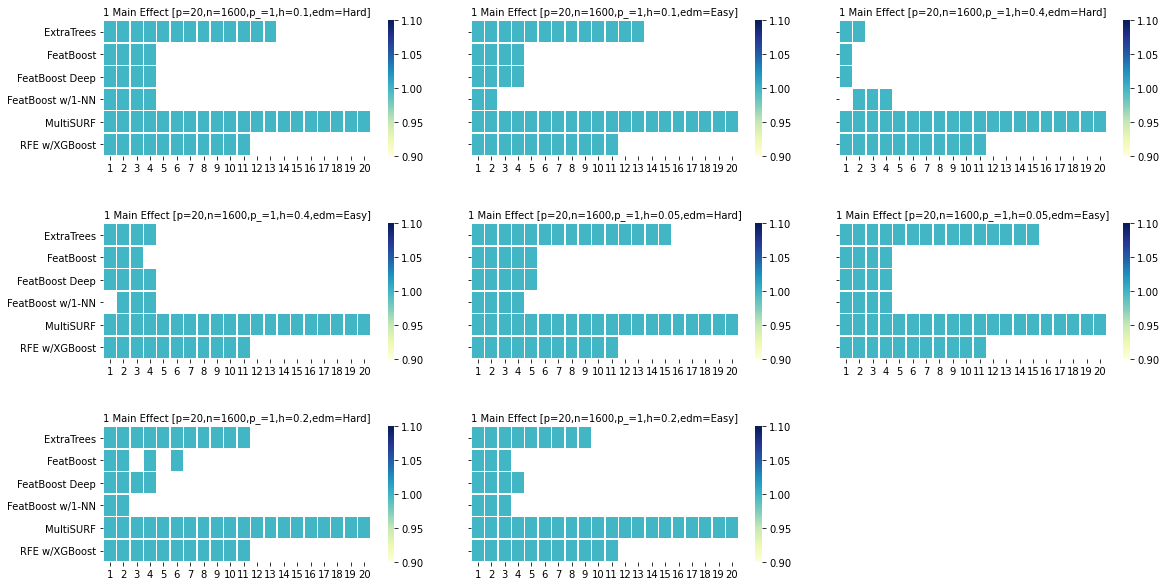

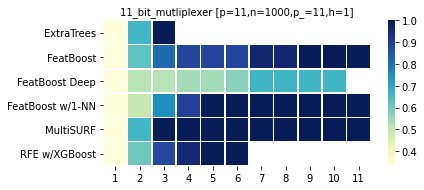

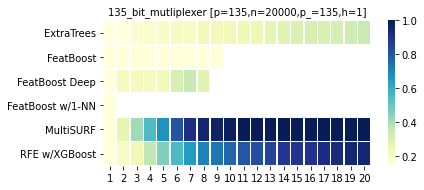

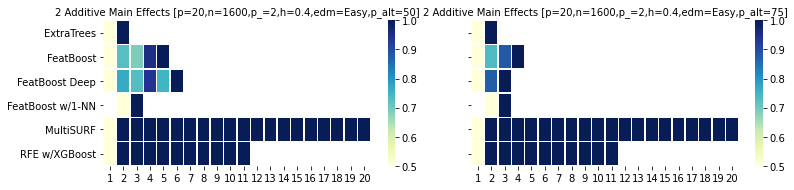

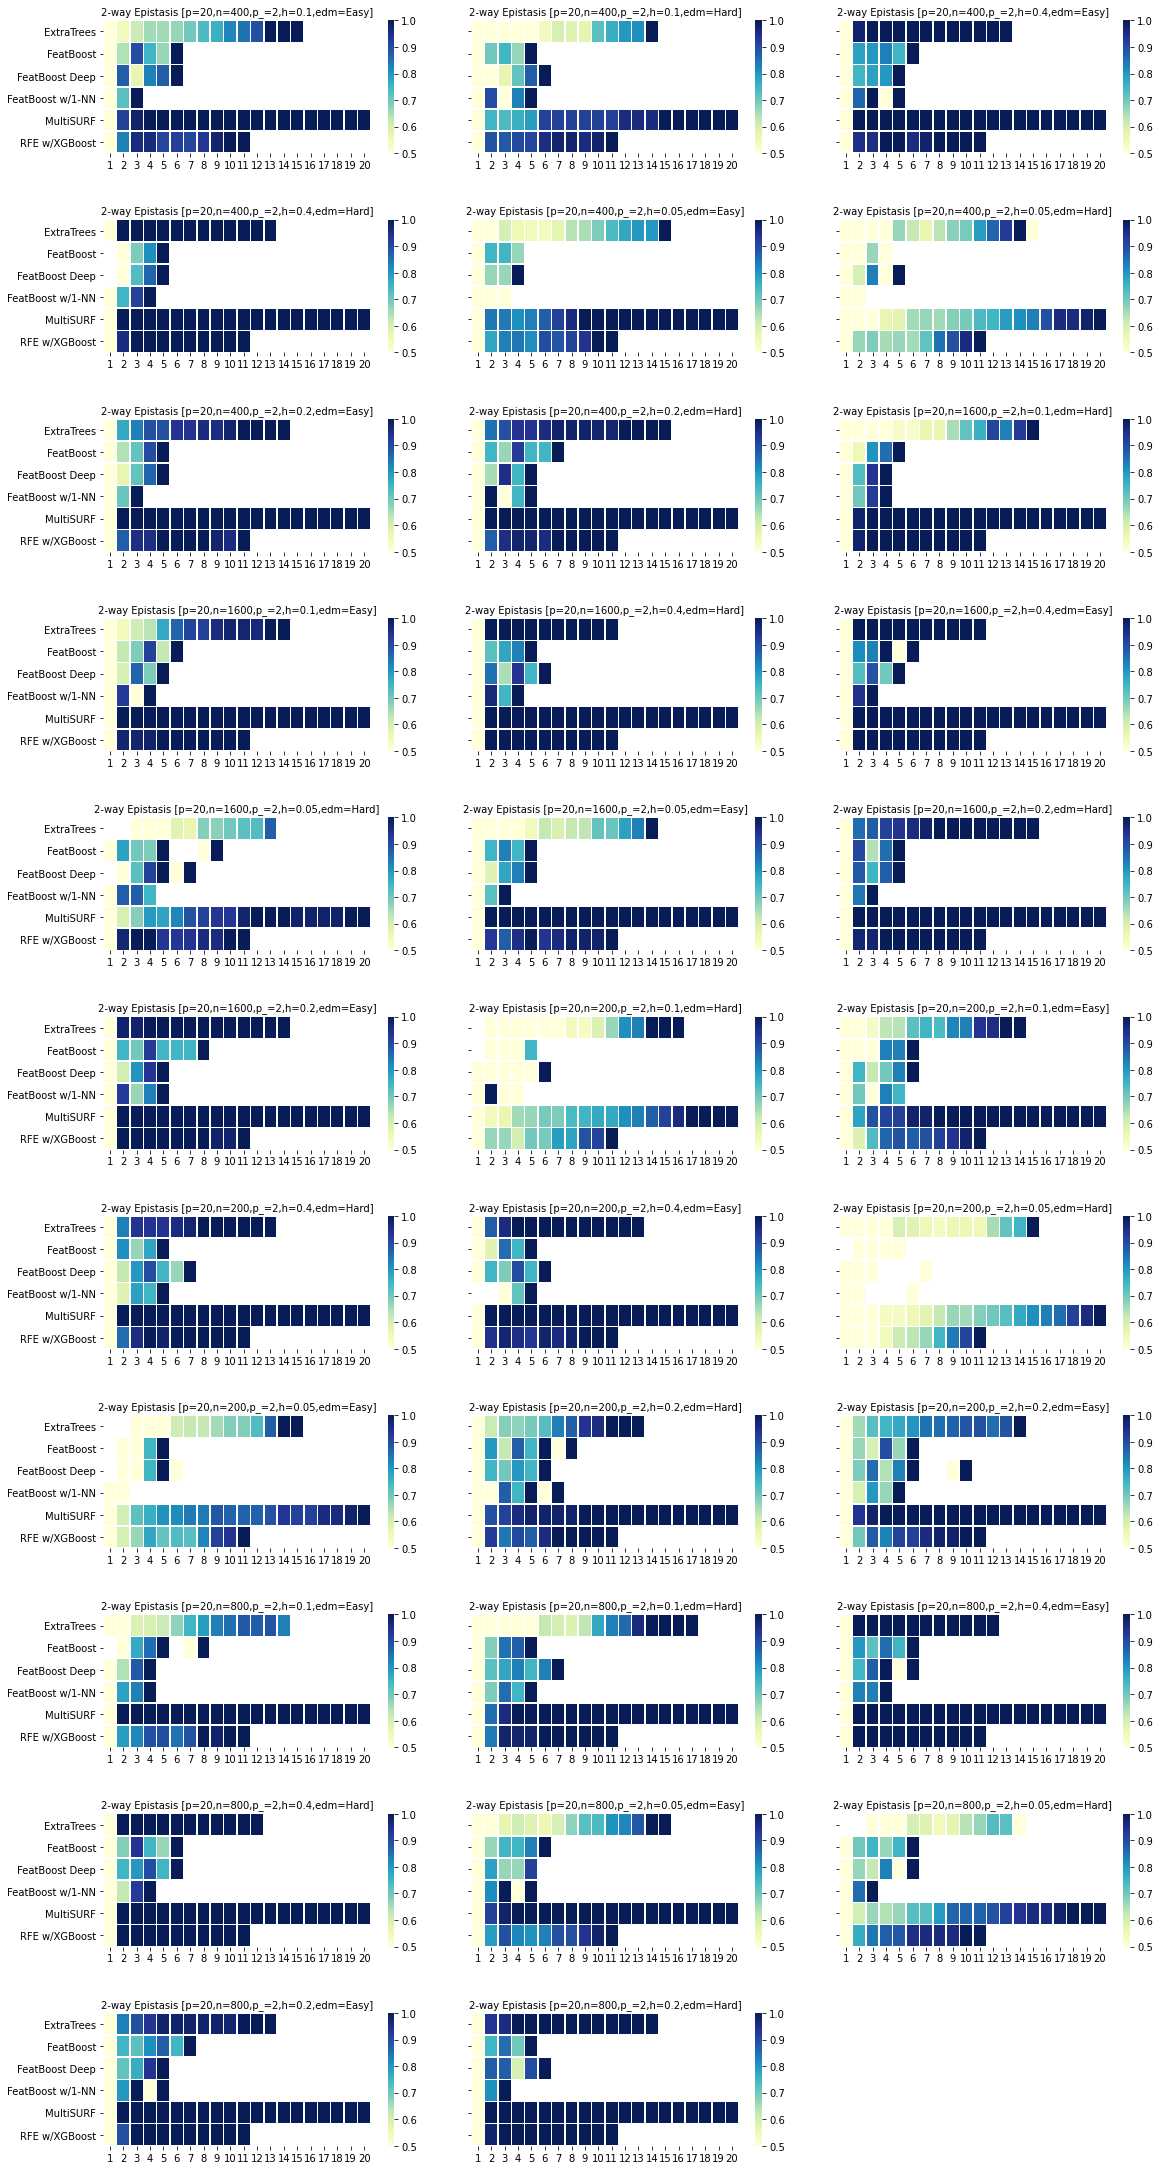

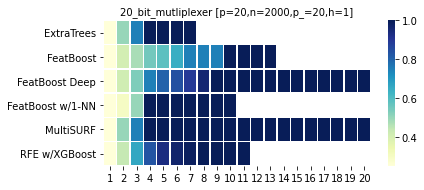

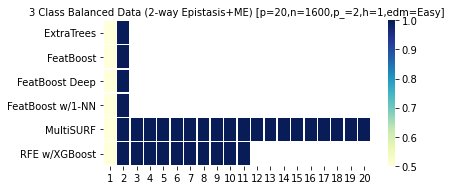

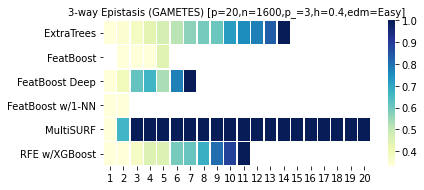

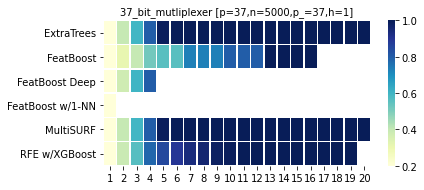

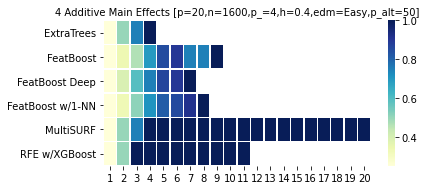

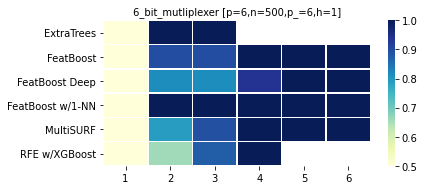

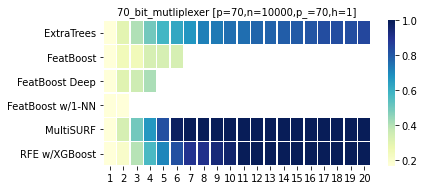

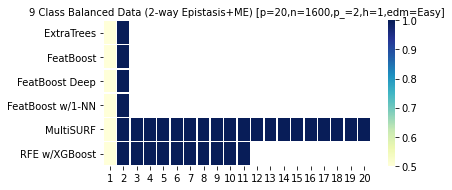

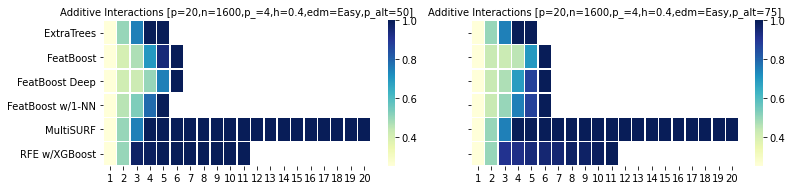

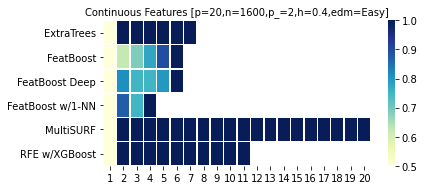

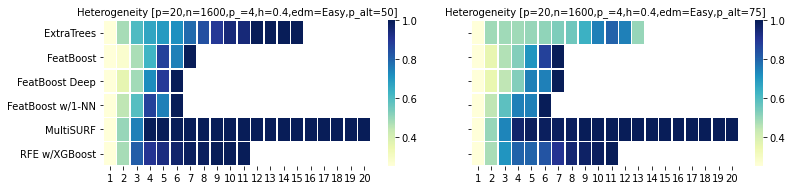

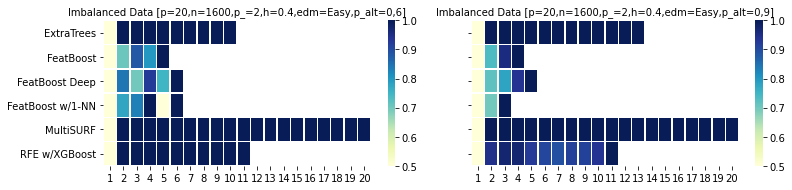

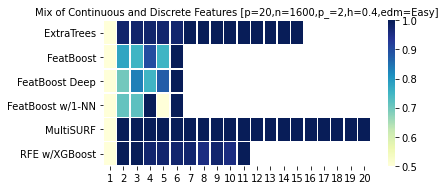

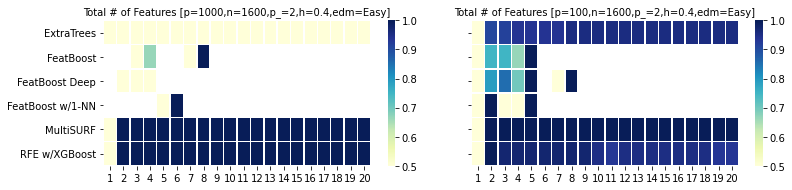

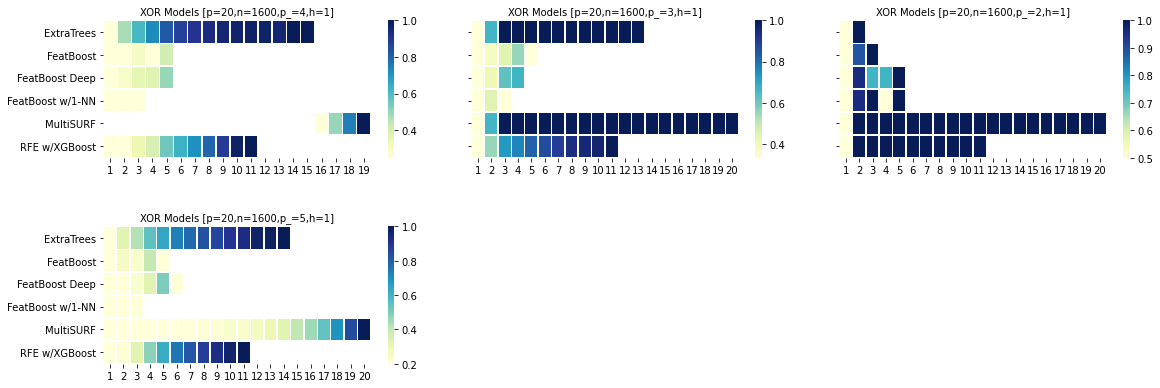

In [8]:
def draw_heatmap(*args, **kwargs):
    data = kwargs.pop('data')
    rect = pd.pivot_table(data, values='recall',\
                        index=['ranking_method'],\
                        columns=['feature_rank'])
    sns.heatmap(rect, linewidths=.5, cmap="YlGnBu")
    plt.gca().xaxis.set_major_formatter(FuncFormatter(lambda x, _: int(x) + 1))
    plt.yticks(rotation=0)
    plt.xticks(rotation=0)

def pltrecall(data, title):
    fg = sns.FacetGrid(data, col='description', sharex=False, col_wrap=3, size=2.75, aspect=2)
    fg.map_dataframe(draw_heatmap).set_titles("{col_name}")
    fg.fig.subplots_adjust(wspace=0.1, hspace=0.5)
    # plt.subplots_adjust(top=0.875)
    # fg.fig.suptitle(title)
    # fg.fig.tight_layout()

for name, data in subset2.groupby('name'):
    pltrecall(data, name)

Text(0.5, 1.0, 'cpu time per ranking method in seconds')

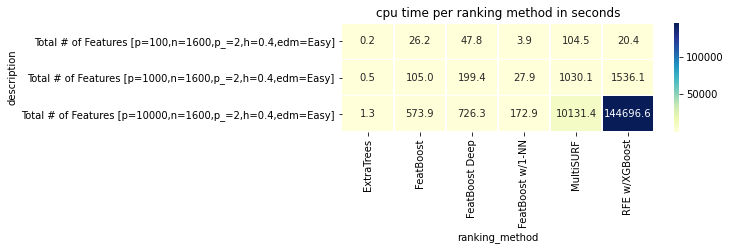

In [33]:
import seaborn as sns
import matplotlib.pyplot as plt
pivot = pd.pivot_table(subset,\
    values='cpu_time', index=['description'], columns=['ranking_method'])
f, ax = plt.subplots(figsize=(7, 20))
ax = sns.heatmap(pivot, annot=True, fmt=".1f", linewidths=.5, cmap="YlGnBu", yticklabels=True, ax=ax)
plt.title('cpu time per ranking method in seconds')

In [29]:
totfeatures = statdata.copy()
totfeatures = totfeatures[totfeatures['description'] == 'Total # of Features [p=10000,n=1600,p_=2,h=0.4,edm=Easy]']
totfeatures = totfeatures[totfeatures['replica_no'] == 1]
totfeatures = totfeatures[totfeatures['ranking_method'] == 'FeatBoost w/1-NN']
totfeatures

,cpu_time,feature_rank,ranking_method,replica_no,name,description,recall,precision,fpr,f1,auc
84521,172.608291,1.0,FeatBoost w/1-NN,1,Total # of Features,"Total # of Features [p=10000,n=1600,p_=2,h=0.4...",0.0,0.0,0.0001,NaN,0.49995
